# Interleaving maps

Visualize fitted interleaving maps for a loop and a line, then for the more complex Mapper graphs from the interleaving basics tutorial.

In [1]:
import matplotlib.pyplot as plt
from cereeberus import Interleave
from cereeberus.data.ex_mappergraphs import line, torus
from cereeberus.draw.metromaps import color_by_arc, draw_metromaps

F = torus(0, 2, 8, 10, delta=1, seed=17)
G = line(0, 12, seed=5)
interleaving = Interleave(F, G)
n = interleaving.fit()


## Color by arc

Each source arc keeps one color along its ILP-selected image. The top row shows $F \to G^n$ and the bottom row shows $G \to F^n$. The panel titles display the fitted value of $n$.

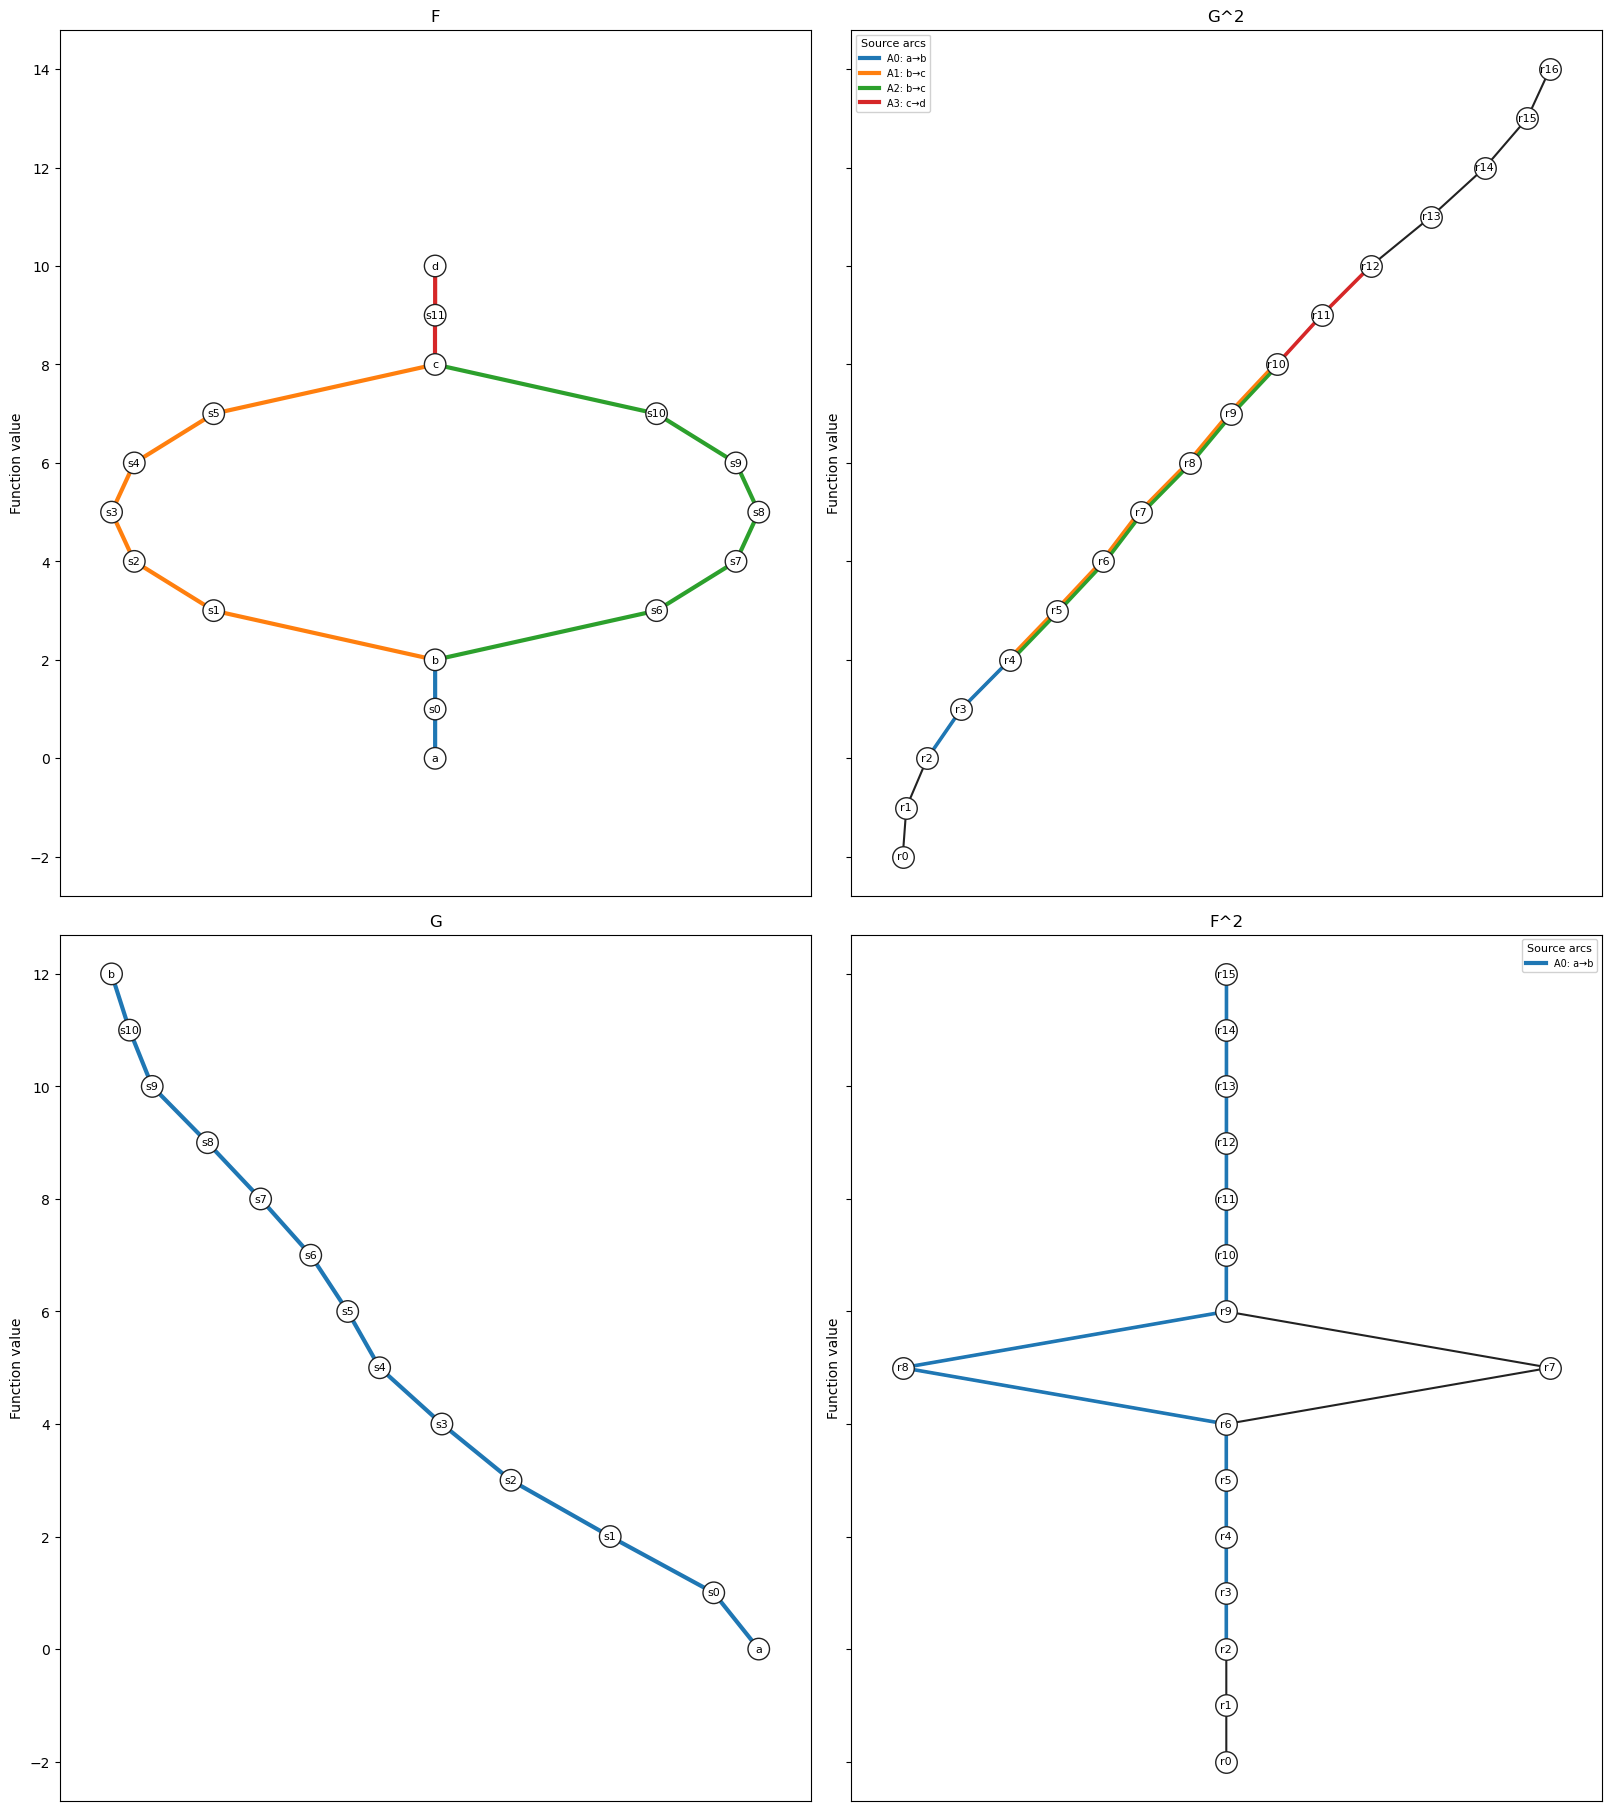

In [2]:
fig = draw_metromaps(interleaving, color_by="arc", show_vert_maps=False, level_set_colors=False, sharey=True, figsize=(16, 18))
plt.show()


## Color by edge

Give each source edge its own color to inspect the individual ILP assignments.

/Users/ishikaghosh/Library/CloudStorage/OneDrive-MichiganStateUniversity/Documents/Research/Projects/Interleaving_to_ML/ceREEBerus/cereeberus/cereeberus/draw/metromaps.py:301: UserWarning: Color scheme 'tab10' has 10 colors for 16 source groups; colors will repeat. Choose a different color_scheme or use color_by='arc'.
  _draw_pair(assignment, map_name, key, axes[row],
/Users/ishikaghosh/Library/CloudStorage/OneDrive-MichiganStateUniversity/Documents/Research/Projects/Interleaving_to_ML/ceREEBerus/cereeberus/cereeberus/draw/metromaps.py:301: UserWarning: Color scheme 'tab10' has 10 colors for 12 source groups; colors will repeat. Choose a different color_scheme or use color_by='arc'.
  _draw_pair(assignment, map_name, key, axes[row],


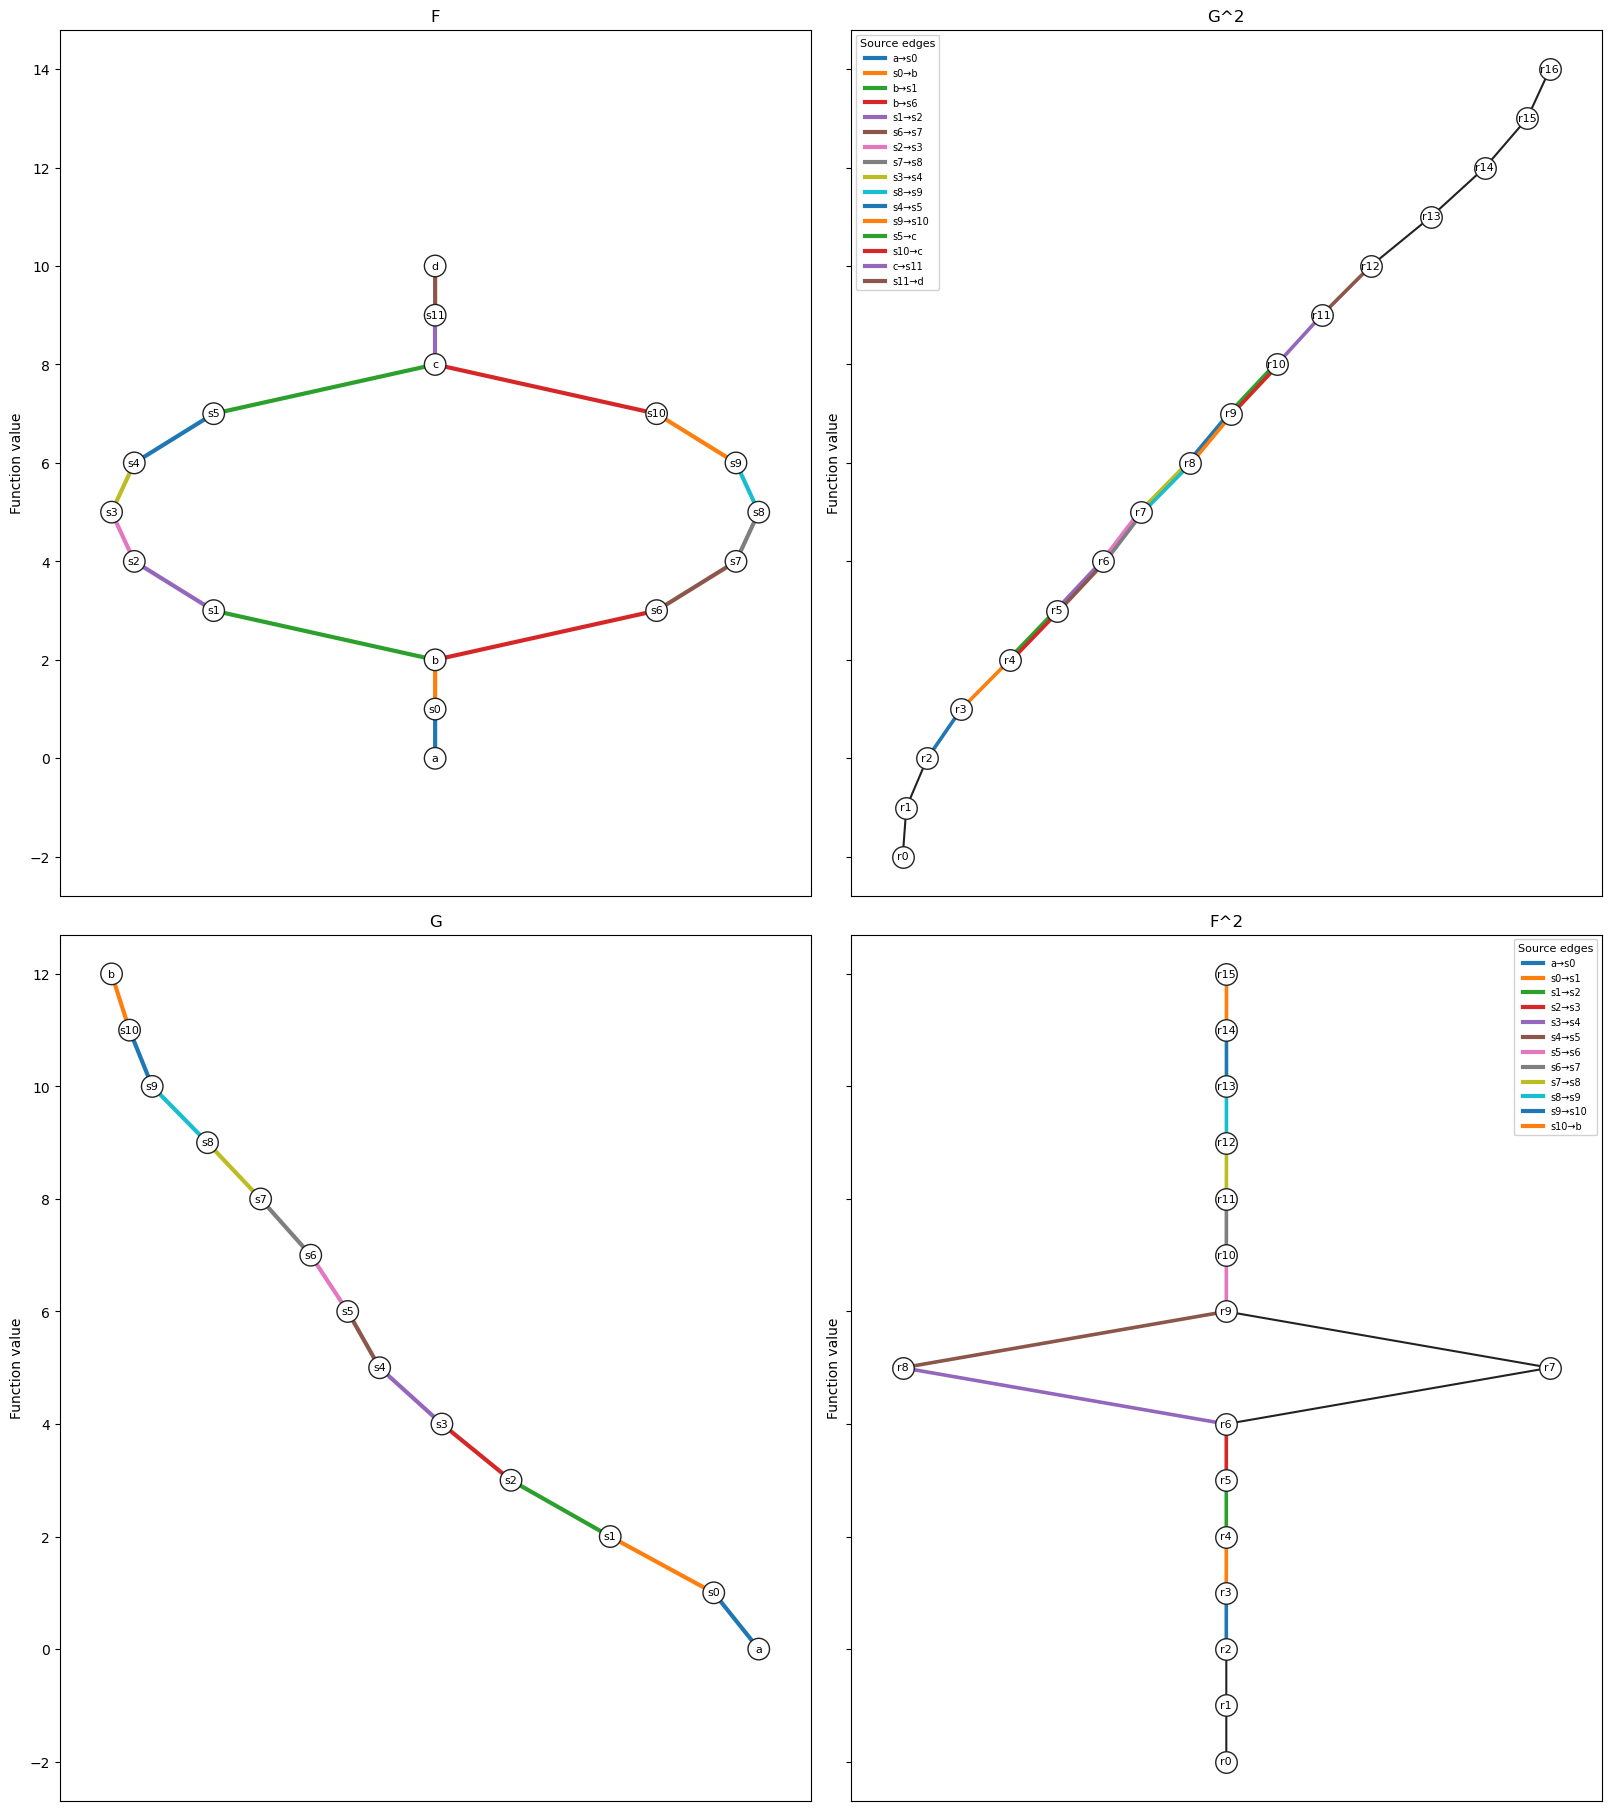

In [3]:
fig = draw_metromaps(interleaving, color_by="edge", show_vert_maps=False, level_set_colors=False, sharey=True, figsize=(16, 18))
plt.show()


## Follow one arc

Select arc `A1` of $F$ and highlight all its mapped edge images in $G^n$.

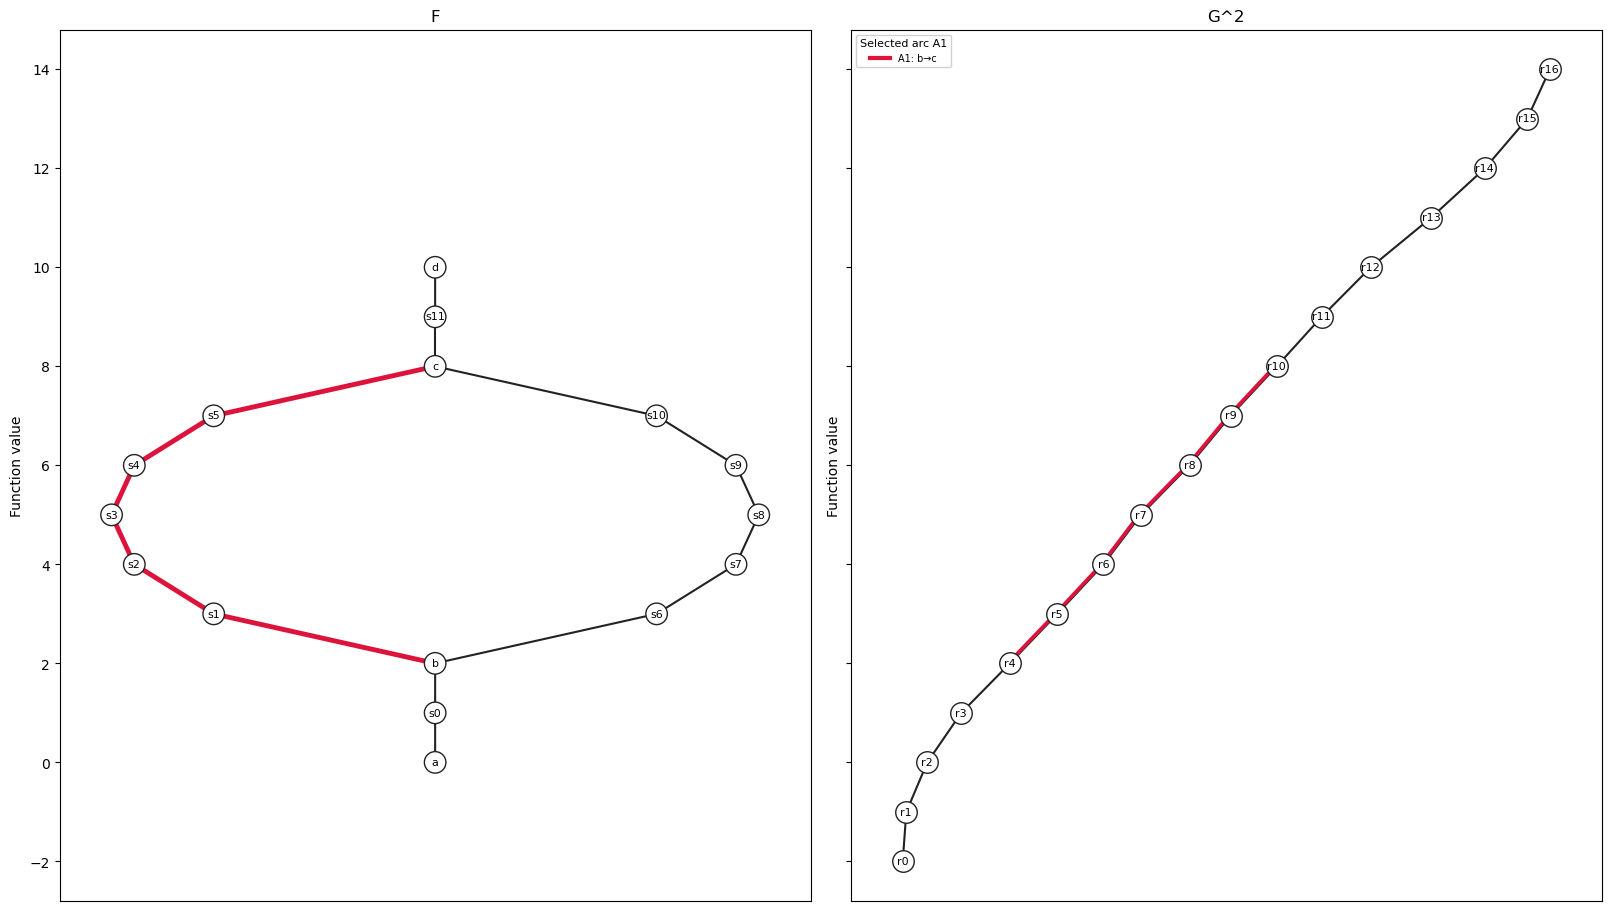

In [4]:
fig = color_by_arc(interleaving, 1, direction="phi", figsize=(16, 9))
plt.show()


## More complex Mapper graphs

These are the same two graphs used in the [interleaving basics tutorial](interleaving_basics.ipynb). They contain several extrema, junctions, and loops. First inspect the inputs, then follow their arcs through the fitted maps.

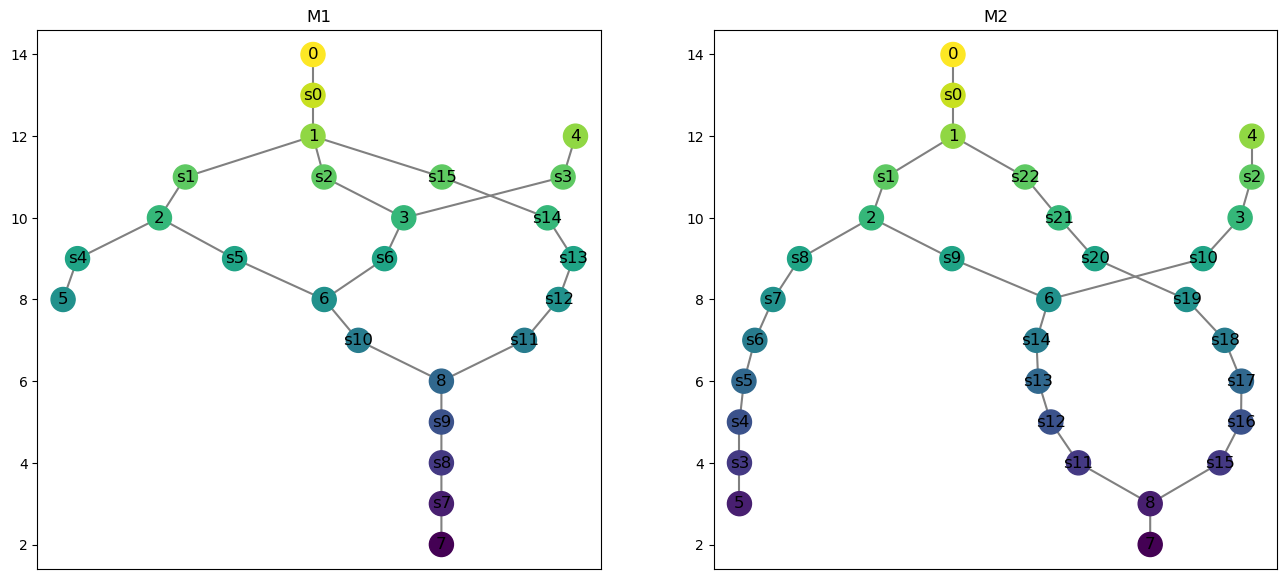

In [5]:
from cereeberus.data.ex_mappergraphs import interleave_example_A, interleave_example_B

M1 = interleave_example_A(seed=17)
M2 = interleave_example_B(seed=5)
M1.name, M2.name = "M1", "M2"
M1.set_pos_from_f(seed=17)
M2.set_pos_from_f(seed=5)

fig, axes = plt.subplots(1, 2, figsize=(16, 7), sharey=True)
for graph, ax in zip((M1, M2), axes):
    graph.draw(ax=ax)
    ax.set_title(graph.name)
plt.show()


### Interleaving maps colored by arc

Each source arc has a matching color on its ILP-selected target edges. The top row shows $M1 \to M2^n$; the bottom row shows $M2 \to M1^n$. Set `show_vert_maps=True` to also annotate the vertex maps.

Source and target panels share the same height scale, so equal function values line up horizontally. Use `level_set_colors=True` to color vertices by height.

Fitted smoothing parameter: n = 4


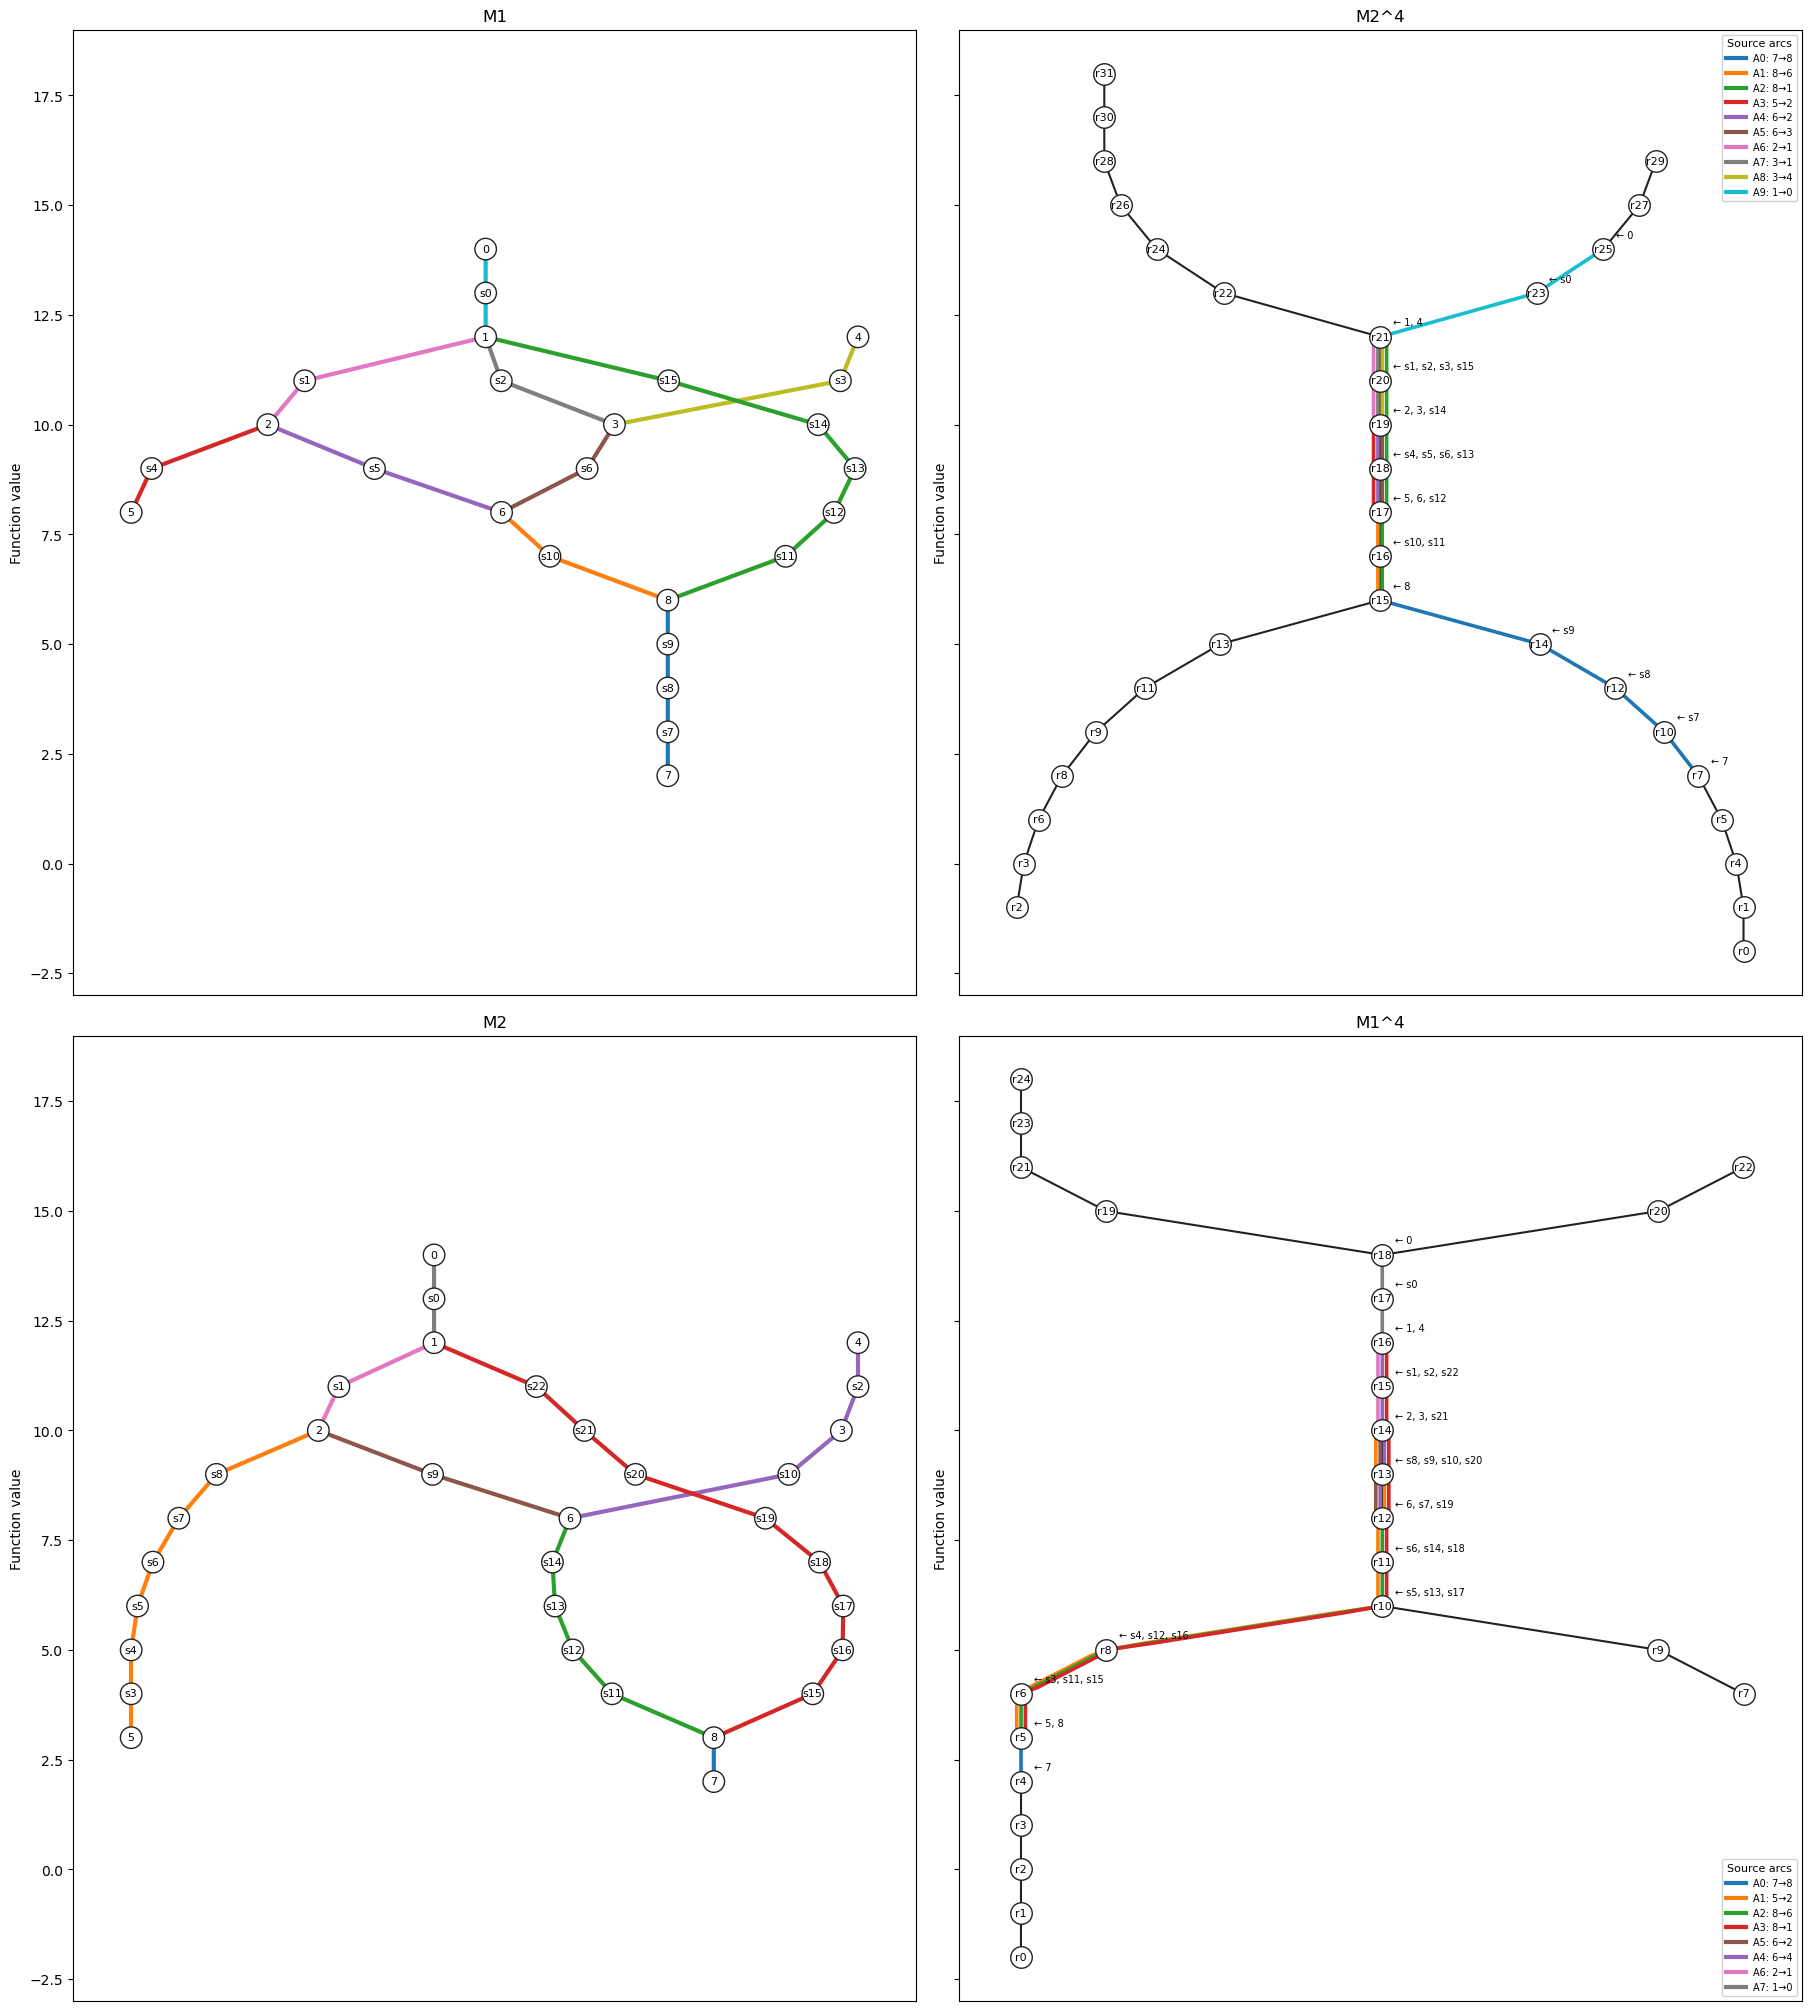

In [6]:
complex_interleaving = Interleave(M1, M2)
complex_n = complex_interleaving.fit()
print(f"Fitted smoothing parameter: n = {complex_n}")

fig = draw_metromaps(
    complex_interleaving,
    color_by="arc",
    show_vert_maps=True, level_set_colors=False, sharey=True,
    figsize=(18, 20),
)
plt.show()
